# Modelos Matemáticos y Estadísticos Clásicos
## Diplomado en Data Science 2026

---

## Taller 2


**Integrantes**:

- Jaysson Leon
- Nadia Lell
- Matias Reyes
- Kelly Martinez


## Caso: Empresa de comercio electrónico

Formas parte del equipo de Data Science de una empresa de comercio electrónico. Un analista del equipo ha estado trabajando en distintos problemas relacionados con operación, tiempos de entrega, riesgo de atraso y planificación de demanda.

Tu tarea **no consiste solamente en ejecutar modelos**. Durante esta evaluación deberás revisar el trabajo del analista, decidir si sus conclusiones son correctas, proponer mejoras cuando corresponda y justificar tus decisiones.

### Objetivos evaluados

Se espera que seas capaz de:

- identificar qué herramienta estadística es apropiada para una pregunta;
- distinguir entre una asociación descriptiva, evidencia estadística y causalidad;
- interpretar correctamente resultados y métricas;
- detectar cuándo una conclusión **sí** está respaldada por los datos y cuándo **no**;
- comparar modelos y justificar cuál utilizarías.

### Importante

- El código de preparación de datos ya está entregado y **no forma parte de la evaluación**.
- Puedes agregar las celdas de código o texto que estimes necesarias.
- Toda conclusión debe estar respaldada por resultados reproducibles en el notebook.
- No se evaluará la cantidad de código, sino la calidad del análisis.

---

#  Preparación de datos

El siguiente código construye una tabla analítica a nivel de pedido a partir de cuatro tablas de origen.

**No es necesario modificar esta sección.**


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import statsmodels.api as sm
import statsmodels.formula.api as smf

from scipy import stats
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    roc_auc_score,
    mean_absolute_error,
    root_mean_squared_error
)
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.statespace.sarimax import SARIMAX

pd.set_option("display.max_columns", 100)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

URL_CUSTOMERS = "https://docs.google.com/spreadsheets/d/13l1up9hqmT8a3z1fj7283gEttstJ8tVFHpzxvwHpp4E/export?format=csv"
URL_ORDER_ITEMS = "https://docs.google.com/spreadsheets/d/1QkCG0Mt4GugaG7pRxnnafE3GulXoqUrkdo2sRFlfpCY/export?format=csv"
URL_ORDERS = "https://docs.google.com/spreadsheets/d/17_OkQhApsLwNoXpb8-63cVQ_zwu5uiQXiYZnpWBeEz8/export?format=csv"
URL_PRODUCTS = "https://docs.google.com/spreadsheets/d/1pN4sFbqEaZVuCQpkkDo-IZB7EgqMOyGUMfoZTbRaOo0/export?format=csv"

customers = pd.read_csv(URL_CUSTOMERS)
order_items = pd.read_csv(URL_ORDER_ITEMS)
orders = pd.read_csv(URL_ORDERS)
products = pd.read_csv(URL_PRODUCTS)

print("customers:", customers.shape)
print("order_items:", order_items.shape)
print("orders:", orders.shape)
print("products:", products.shape)


customers: (15150, 5)
order_items: (16767, 7)
orders: (15000, 8)
products: (9208, 9)


In [2]:
for col in [
    "order_item_id",
    "price",
    "freight_value"
]:
    if col in order_items.columns:
        order_items[col] = pd.to_numeric(
            order_items[col],
            errors="coerce"
        )

for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(
            products[col],
            errors="coerce"
        )


# Fechas
date_cols = [
    "order_purchase_timestamp",
    "order_approved_at",
    "order_delivered_carrier_date",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_cols:
    if col in orders.columns:
        orders[col] = pd.to_datetime(
            orders[col],
            errors="coerce",
            format="mixed"
        )

# Variables geométricas de productos
for col in [
    "product_weight_g",
    "product_length_cm",
    "product_height_cm",
    "product_width_cm"
]:
    if col in products.columns:
        products[col] = pd.to_numeric(products[col], errors="coerce")

if all(c in products.columns for c in ["product_length_cm", "product_height_cm", "product_width_cm"]):
    products["product_volume_cm3"] = (
        products["product_length_cm"]
        * products["product_height_cm"]
        * products["product_width_cm"]
    )

# Enriquecer ítems con atributos de producto
items_prod = order_items.merge(
    products[
        [c for c in [
            "product_id",
            "product_category_name",
            "product_weight_g",
            "product_volume_cm3"
        ] if c in products.columns]
    ],
    on="product_id",
    how="left"
)

# Agregación a nivel de pedido
agg_dict = {
    "n_items": ("order_item_id", "count"),
    "total_price": ("price", "sum"),
    "total_freight": ("freight_value", "sum"),
    "avg_item_price": ("price", "mean"),
    "n_products": ("product_id", "nunique"),
}

if "product_category_name" in items_prod.columns:
    agg_dict["n_categories"] = ("product_category_name", "nunique")
if "product_weight_g" in items_prod.columns:
    agg_dict["total_weight_g"] = ("product_weight_g", "sum")
if "product_volume_cm3" in items_prod.columns:
    agg_dict["total_volume_cm3"] = ("product_volume_cm3", "sum")

order_agg = (
    items_prod
    .groupby("order_id")
    .agg(**agg_dict)
    .reset_index()
)

# Tabla analítica
df = (
    orders
    .merge(customers, on="customer_id", how="left")
    .merge(order_agg, on="order_id", how="left")
)

# Variables derivadas
df["purchase_date"] = df["order_purchase_timestamp"].dt.floor("D")
df["purchase_weekday"] = df["order_purchase_timestamp"].dt.day_name()
df["purchase_month"] = df["order_purchase_timestamp"].dt.to_period("M").astype(str)
df["is_weekend_purchase"] = df["order_purchase_timestamp"].dt.dayofweek.ge(5).astype(int)

df["delivery_days"] = (
    df["order_delivered_customer_date"] - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400

df["delay_days"] = (
    df["order_delivered_customer_date"] - df["order_estimated_delivery_date"]
).dt.total_seconds() / 86400

df["days_to_carrier"] = (
    df["order_delivered_carrier_date"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 86400


df["remaining_days"] = (
    df["order_estimated_delivery_date"]
    - df["order_delivered_carrier_date"]
).dt.total_seconds() / 86400

df["approval_hours"] = (
    df["order_approved_at"]
    - df["order_purchase_timestamp"]
).dt.total_seconds() / 3600


df["late_delivery"] = np.where(
    df["order_delivered_customer_date"].notna()
    & df["order_estimated_delivery_date"].notna(),
    (df["delay_days"] > 0).astype(int),
    np.nan
)

df["freight_ratio"] = df["total_freight"] / df["total_price"].replace(0, np.nan)

# Solo pedidos entregados para análisis de tiempos
delivered = df[
    (df["order_status"] == "delivered")
    & df["delivery_days"].notna()
].copy()

print("Tabla analítica:", df.shape)
print("Pedidos entregados:", delivered.shape)

display(delivered.head())


Tabla analítica: (15150, 31)
Pedidos entregados: (14688, 31)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state,n_items,total_price,total_freight,avg_item_price,n_products,n_categories,total_weight_g,total_volume_cm3,purchase_date,purchase_weekday,purchase_month,is_weekend_purchase,delivery_days,delay_days,days_to_carrier,remaining_days,approval_hours,late_delivery,freight_ratio
0,3b14820d642ea72e95df3289b6539c1c,4248fddd68e3375c24e743290ce2d9fa,delivered,2018-04-02 13:01:06,2018-04-02 13:10:21,2018-04-04 23:42:34,2018-04-12 17:12:13,2018-04-23,a79c62e50e66e1036ba2cb2e5e00aff3,37190,tres pontas,MG,1.000,75.900,19.500,75.900,1.000,1.000,700.000,"6,912.000",2018-04-02,Monday,2018-04,0,10.174,-10.283,2.445,18.012,0.154,0.000,0.257
1,8a795486f112df15565463862960aa40,e093120ffd5c259e2decb4ff5266f0dd,delivered,2018-05-20 20:28:32,2018-05-22 09:36:09,2018-05-22 15:48:00,2018-06-01 11:50:31,2018-05-29,81ec41f3b0c51a9df15c5957140686fa,13084,campinas,SP,1.000,95.900,11.300,95.900,1.000,1.000,"1,400.000","27,000.000",2018-05-20,Sunday,2018-05,1,11.640,3.493,1.805,6.342,37.127,1.000,0.118
2,7aa2471c1e8d0cd89eec9459fde59414,0eb400f3e6d2f08e70d2ab5af9c203f4,delivered,2017-09-18 19:09:52,2017-09-20 02:10:42,2017-09-21 19:37:10,2017-09-27 19:09:10,2017-10-04,c64b0bf5855e1d6ba223d649298c2915,36889,muriae,MG,1.000,81.000,42.710,81.000,1.000,1.000,"18,100.000","4,332.000",2017-09-18,Monday,2017-09,0,9.000,-6.202,3.019,12.183,31.014,0.000,0.527
3,95cf53396116b5dd518b5ba1c11a0bb5,3b2e666d92ce663a2f35ba3a6bb5df6a,delivered,2017-04-21 19:31:13,2017-04-21 19:45:10,2017-04-25 13:08:20,2017-05-04 16:46:54,2017-05-19,4113a7e912e87f632986e0562da140c7,74075,goiania,GO,1.000,59.000,17.840,59.000,1.000,1.000,275.000,"1,936.000",2017-04-21,Friday,2017-04,0,12.886,-14.301,3.734,23.453,0.233,0.000,0.302
4,6c5eb0920626d3ff5588d03d6f2d4936,1b83beaaa59c8cdfe738f7ead2517da8,delivered,2018-03-15 15:22:28,2018-03-17 03:08:57,2018-03-19 21:14:58,2018-05-03 11:29:52,2018-04-30,d69a93bce76b26886f72125e60b01cec,69040,manaus,AM,1.000,69.900,57.040,69.900,1.000,1.000,"1,200.000","21,000.000",2018-03-15,Thursday,2018-03,0,48.838,3.479,4.245,41.115,35.775,1.000,0.816


### Diccionario resumido de la tabla analítica

| Variable | Descripción |
|---|---|
| `order_id` | Identificador del pedido |
| `customer_state` | Estado/región del cliente |
| `purchase_date` | Fecha de compra |
| `purchase_weekday` | Día de la semana de compra |
| `is_weekend_purchase` | 1 si la compra se realizó sábado o domingo |
| `n_items` | Número de ítems del pedido |
| `n_products` | Número de productos distintos |
| `n_categories` | Número de categorías distintas, si está disponible |
| `total_price` | Valor total de los productos |
| `total_freight` | Valor total del despacho |
| `avg_item_price` | Precio promedio de los ítems |
| `total_weight_g` | Peso total aproximado de los productos |
| `total_volume_cm3` | Volumen total aproximado |
| `delivery_days` | Días transcurridos desde compra hasta entrega |
| `delay_days` | Días de diferencia respecto de la fecha comprometida |
| `days_to_carrier` | Número de días transcurridos desde que se realiza la compra hasta que el pedido es entregado al transportista. |
| `remaining_days` | Número de días disponibles entre la entrega del pedido al transportista y la fecha estimada de entrega al cliente. |
| `approval_hours` | Número de horas transcurridas desde que se realiza la compra hasta que el pedido es aprobado. |
| `late_delivery` | 1 si el pedido llegó después de la fecha comprometida |
| `freight_ratio` | Costo de despacho dividido por valor de productos |

---




## Primer bloque (20 puntos)

El analista preparó la siguiente tabla cruzada entre **tamaño del pedido** y **atraso**.

Primero creó dos grupos:

- `1_item`: pedidos con un solo ítem;
- `2_o_mas`: pedidos con dos o más ítems.

In [3]:
analisis_1 = delivered[
    delivered["late_delivery"].notna()
    & delivered["n_items"].notna()
].copy()

analisis_1["grupo_items"] = np.where(
    analisis_1["n_items"] == 1,
    "1_item",
    "2_o_mas"
)

tabla = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"]
)

tabla


late_delivery,0.000,1.000
grupo_items,,
1_item,12054,1080
2_o_mas,1309,96


El analista luego calculó dos tablas:



In [4]:
# Tabla A
tabla_fila = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="index"
)

tabla_fila


late_delivery,0.000,1.000
grupo_items,,
1_item,0.918,0.082
2_o_mas,0.932,0.068


In [5]:
# Tabla B
tabla_columna = pd.crosstab(
    analisis_1["grupo_items"],
    analisis_1["late_delivery"],
    normalize="columns"
)

tabla_columna


late_delivery,0.000,1.000
grupo_items,,
1_item,0.902,0.918
2_o_mas,0.098,0.082



El analista afirma:

> "El analista observa que en la Tabla B el valor asociado a 1_item y late_delivery=1 es 0,918 y concluye que “los pedidos de un ítem tienen 91,8% de probabilidad de atraso”. ¿Es correcta esta interpretación?"


1. Explique qué representa el valor 0,082 de la Tabla A.  

2. Explique qué representa el valor 0,918 de la Tabla B.

3. ¿Cuál de las dos tablas permite comparar la probabilidad de atraso entre
pedidos de 1 ítem y de 2 o más ítems?

4. ¿Los resultados descriptivos apoyan la hipótesis del analista?

5. Evalúe si la diferencia observada es solo una cuestión de la muestra. Considere y explicite los supuestos/límites necesarios.

6. ¿Puede concluir que cambiar el número de ítems de un pedido modifica causalmente su probabilidad de atraso? Explique.

### Tu análisis


In [6]:
# Test de chi-cuadrado: ¿el atraso depende del tamaño del pedido o la diferencia
# que vimos en las tablas puede ser solo azar?
chi2, p_valor, gl, esperado = stats.chi2_contingency(tabla)

print(f"chi2 = {chi2:.3f} | grados de libertad = {gl} | p-valor = {p_valor:.4f}")

# Comparamos directamente las dos probabilidades de atraso (ya están en tabla_fila)
p_1item = tabla_fila.loc["1_item", 1.0]
p_2omas = tabla_fila.loc["2_o_mas", 1.0]

print(f"\nP(atraso | 1_item)  = {p_1item:.3f}")
print(f"P(atraso | 2_o_mas) = {p_2omas:.3f}")
print(f"Diferencia          = {p_1item - p_2omas:.3f}")

if p_valor < 0.05:
    print("\n=> p-valor < 0.05: la diferencia entre grupos es estadísticamente "
          "significativa, no se explica solo por azar muestral.")
else:
    print("\n=> p-valor >= 0.05: la diferencia observada es compatible con azar "
          "muestral; no hay evidencia estadística suficiente de una diferencia real "
          "entre los grupos.")


chi2 = 3.115 | grados de libertad = 1 | p-valor = 0.0776

P(atraso | 1_item)  = 0.082
P(atraso | 2_o_mas) = 0.068
Diferencia          = 0.014

=> p-valor >= 0.05: la diferencia observada es compatible con azar muestral; no hay evidencia estadística suficiente de una diferencia real entre los grupos.


Respuesta e interpretación:

1) ¿Qué representa el 0,082 de la Tabla A?

La Tabla A está normalizada por fila (`normalize="index"`), así que cada fila suma 1. El 0,082 significa: de todos los pedidos que tienen 1 solo ítem, el 8,2% llegó atrasado. En notación de probabilidad condicional: P(atraso | 1_item) = 0,082. Se fija primero el grupo (1 ítem) y se mira qué porcentaje de ese grupo se atrasa.

2) ¿Qué representa el 0,918 de la Tabla B?

La Tabla B está normalizada por columna (`normalize="columns"`), cada columna suma 1. El 0,918 significa otra cosa distinta: de todos los pedidos que llegaron atrasados, el 91,8% eran pedidos de 1 solo ítem. Es P(1_item | atraso) = 0,918. Aquí se fija primero el resultado (atraso) y se mira de qué grupo venían.

Son dos preguntas distintas aunque suenen parecidas, y no se puede usar una por la otra. El 91,8% es tan alto principalmente porque la mayoría de los pedidos de la tabla son de 1 ítem (unos 9 de cada 10 pedidos), no porque ese grupo tenga un riesgo particularmente alto de atraso.

3) ¿Cuál tabla permite comparar la probabilidad de atraso entre grupos?

La Tabla A. Para comparar el riesgo de atraso entre "1 ítem" y "2 o más ítems" necesitamos fijar el grupo y ver qué porcentaje de cada uno se atrasa, que es justo lo que hace la Tabla A: 8,2% vs. 6,8%. La Tabla B no sirve para esto porque mezcla la comparación con qué tan grande es cada grupo dentro de la muestra total.

4) ¿Los resultados descriptivos apoyan la hipótesis del analista?

No, tal como está planteada. El analista dijo que los pedidos de 1 ítem tienen "91,8% de probabilidad de atraso", pero ese número (de la Tabla B) no es una probabilidad de atraso, es la proporción de pedidos atrasados que vienen del grupo de 1 ítem. La probabilidad real de atraso para ese grupo es 8,2% (Tabla A).

Sí es cierto que los pedidos de 1 ítem se atrasan un poco más que los de 2 o más (8,2% vs. 6,8%, una diferencia de 1,4 puntos porcentuales), pero es una diferencia bastante chica, no del tamaño que el analista sugirió.

5) ¿Es la diferencia observada solo cuestión de la muestra?

Aplicamos un test de chi-cuadrado de independencia sobre la tabla de conteos original (`tabla`). Resultado: chi2 = 3,115, con 1 grado de libertad, p-valor = 0,0776.

Como el p-valor (0,078) es mayor al umbral habitual de 0,05, no tenemos evidencia suficiente para decir que el atraso y el tamaño del pedido estén realmente relacionados: la diferencia de 1,4 puntos porcentuales que vimos podría deberse simplemente a variación muestral (azar), no a una relación real entre las dos variables.

A tener en cuenta:
El grupo "2_o_mas" tiene bastantes menos pedidos que "1_item" (1.405 vs. 13.134), lo que hace más difícil detectar diferencias chicas aunque existan, es decir, "no significativo" no es lo mismo que "no hay ninguna diferencia", puede que con más datos del grupo chico sí se viera algo.

6) ¿Se puede concluir causalidad?

No. Estos son datos observacionales: nadie decidió al azar cuántos ítems tendría cada pedido, así que no podemos decir que agregar o quitar ítems "cause" el atraso. Puede haber otras variables detrás que expliquen ambas cosas a la vez, por ejemplo el tipo de producto, su peso o volumen, la región del cliente o la época del año: estas podrían afectar tanto cuántos ítems compra alguien como si el pedido llega tarde. Para hablar de causalidad haría falta un experimento con asignación aleatoria, o al menos un modelo que controle por esas otras variables y aun así habría que ser cuidadoso antes de afirmar causalidad.

Conclusión: el analista confundió dos probabilidades condicionales distintas (leyó la Tabla B como si fuera la Tabla A). La diferencia real entre grupos, calculada correctamente con la Tabla A, es pequeña y el test de chi-cuadrado (p = 0,078) no permite descartar que sea producto del azar. Con esta evidencia no se puede afirmar ni una asociación fuerte ni una relación causal.


---

# Segundo Bloque (30 puntos)

El equipo está tratando de entender qué determina el costo de despacho de un pedido.

El analista propone dos modelos.

### Modelo A

Utiliza solamente una variable:


In [7]:
freight_data = delivered[
    delivered["total_freight"].notna()
    & delivered["total_weight_g"].notna()
    & delivered["total_volume_cm3"].notna()
    & delivered["total_price"].notna()
].copy()

modelo_A = smf.ols(
    "total_freight ~ total_volume_cm3",
    data=freight_data
).fit()

print(modelo_A.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.410
Model:                            OLS   Adj. R-squared:                  0.410
Method:                 Least Squares   F-statistic:                 1.008e+04
Date:                Sun, 30 Aug 2026   Prob (F-statistic):               0.00
Time:                        23:14:57   Log-Likelihood:                -60952.
No. Observations:               14539   AIC:                         1.219e+05
Df Residuals:                   14537   BIC:                         1.219e+05
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept           15.0518      0.154  

### Modelo B

Se consideró agregar 3 más!

In [8]:
modelo_B = smf.ols(
    """
    total_freight
    ~ total_price
    + total_weight_g
    + total_volume_cm3
    + n_items
    """,
    data=freight_data
).fit()

print(modelo_B.summary())


                            OLS Regression Results                            
Dep. Variable:          total_freight   R-squared:                       0.581
Model:                            OLS   Adj. R-squared:                  0.581
Method:                 Least Squares   F-statistic:                     5033.
Date:                Sun, 30 Aug 2026   Prob (F-statistic):               0.00
Time:                        23:14:57   Log-Likelihood:                -58463.
No. Observations:               14539   AIC:                         1.169e+05
Df Residuals:                   14534   BIC:                         1.170e+05
Df Model:                           4                                         
Covariance Type:            nonrobust                                         
                       coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------------
Intercept            0.6562      0.271  

El analista concluye:

> “El Modelo B es necesariamente mejor porque tiene más variables y un R² mayor.”

Tu tarea es **evaluar críticamente su trabajo**.

Debes:

1. explicar si estás de acuerdo o no con la afirmación;
2. comparar los modelos utilizando criterios estadísticos que consideres pertinentes;
3. interpretar al menos **dos coeficientes** del Modelo B;
4. revisar gráficamente los supuestos/diagnósticos que consideres relevantes;
5. proponer y ajustar un **Modelo C** que consideres mejor especificado. Puedes incorporar variables disponibles en `freight_data`, transformar variables o eliminar variables;
6. recomendar finalmente A, B o C y justificar tu elección.

### Tu análisis


In [9]:
# 1-2. El R² solo no sirve para comparar modelos con distinta cantidad de variables,
# porque siempre sube (o se mantiene igual) al agregar variables, aporten o no.
# Usamos el R² ajustado y el AIC, que sí penalizan agregar variables de más.
from statsmodels.stats.outliers_influence import variance_inflation_factor

print(f"Modelo A -> R2 ajustado: {modelo_A.rsquared_adj:.3f}  |  AIC: {modelo_A.aic:.0f}")
print(f"Modelo B -> R2 ajustado: {modelo_B.rsquared_adj:.3f}  |  AIC: {modelo_B.aic:.0f}")

# Además revisamos si las variables de B están muy correlacionadas entre sí (multicolinealidad)
X_B = sm.add_constant(freight_data[["total_price", "total_weight_g", "total_volume_cm3", "n_items"]])
vif_B = pd.DataFrame({
    "variable": X_B.columns,
    "VIF": [variance_inflation_factor(X_B.values, i) for i in range(X_B.shape[1])]
})
print("\nVIF de los predictores del Modelo B:")
print(vif_B)


Modelo A -> R2 ajustado: 0.410  |  AIC: 121907
Modelo B -> R2 ajustado: 0.581  |  AIC: 116935

VIF de los predictores del Modelo B:
           variable   VIF
0             const 5.845
1       total_price 1.133
2    total_weight_g 3.337
3  total_volume_cm3 3.355
4           n_items 1.096


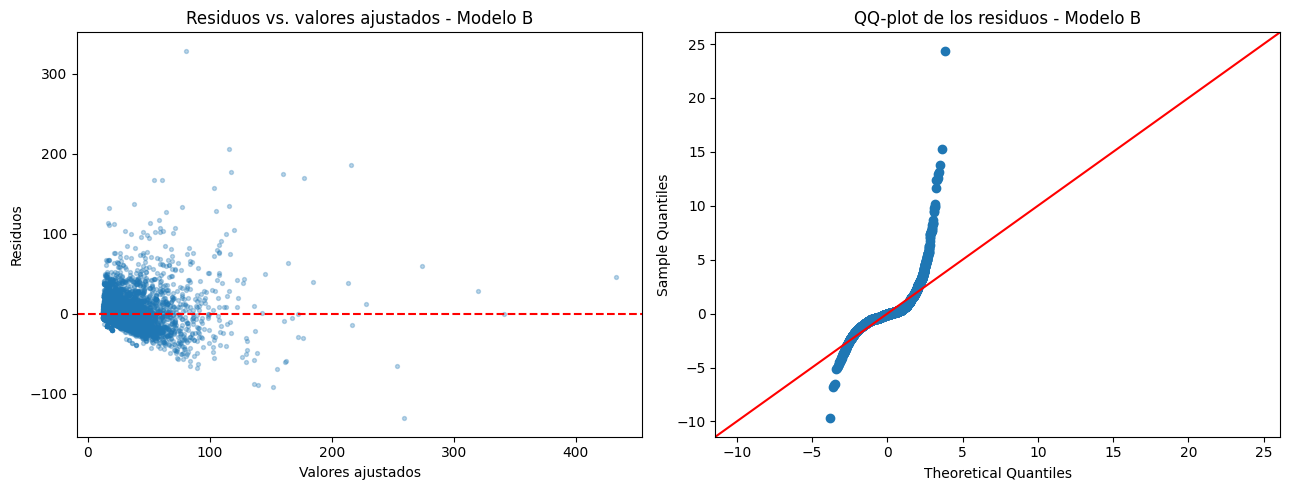

Shapiro-Wilk (normalidad, muestra de 5.000 residuos): estadístico=0.7400, p-valor=1.20e-66
Breusch-Pagan (homocedasticidad): estadístico=1349.29, p-valor=6.85e-291


In [10]:
# 4. Diagnóstico gráfico de los supuestos del Modelo B: normalidad y homocedasticidad
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

axes[0].scatter(modelo_B.fittedvalues, modelo_B.resid, s=8, alpha=0.3)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Valores ajustados")
axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos vs. valores ajustados - Modelo B")

sm.qqplot(modelo_B.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("QQ-plot de los residuos - Modelo B")

plt.tight_layout()
plt.show()

# Tests formales (además de lo que ya reporta el summary en Omnibus/JB)
shapiro_stat, shapiro_p = stats.shapiro(modelo_B.resid.sample(5000, random_state=32))
bp_stat, bp_p, _, _ = sm.stats.diagnostic.het_breuschpagan(modelo_B.resid, modelo_B.model.exog)

print(f"Shapiro-Wilk (normalidad, muestra de 5.000 residuos): estadístico={shapiro_stat:.4f}, p-valor={shapiro_p:.2e}")
print(f"Breusch-Pagan (homocedasticidad): estadístico={bp_stat:.2f}, p-valor={bp_p:.2e}")


Respuesta e interpretación (puntos 1 a 4):

1) y 2) ¿Es correcto decir que B es "necesariamente" mejor?

El razonamiento del analista no es correcto, aunque la conclusión (quedarse con B) sí resulta razonable. El R² siempre sube cuando se agregan variables, así aporten poco o nada dado que es una propiedad matemática de la regresión, no una prueba de que el modelo mejoró de verdad. Por eso hay que usar un criterio que penalice agregar variables de más, como el R² ajustado o el AIC.

En este caso, el R² ajustado sube de 0,41 (Modelo A) a 0,58 (Modelo B), y el AIC baja bastante (de ~121.907 a ~116.935). Entonces sí hay evidencia de que B es un mejor modelo, pero no "porque tiene más variables y más R²", sino porque estos otros criterios también lo confirman.

Sí encontramos un problema en B: `total_weight_g` y `total_volume_cm3` tienen un VIF cercano a 3,3 (mientras que `total_price` y `n_items` están cerca de 1). Esto indica que peso y volumen están bastante correlacionados entre sí y en el fondo, las dos miden algo parecido: qué tan grande es el pedido.

3) Interpretación de dos coeficientes del Modelo B

- `n_items` (coeficiente = 11,71): manteniendo todo lo demás constante, cada ítem adicional del pedido aumenta el despacho en promedio en $11,71.
- `total_weight_g` (coeficiente = 0,0016): manteniendo todo lo demás constante, cada gramo adicional de peso aumenta el despacho en $0,0016, es decir, cerca de $1,6 más por cada kilo adicional.

4) Revisión gráfica de los supuestos

Los gráficos muestran dos problemas:

- Residuos vs. valores ajustados: no forman una nube pareja alrededor de cero, sino que se abren como un embudo esto es una señal de que la varianza de los errores no es constante (heterocedasticidad). El test de Breusch-Pagan lo confirma (p-valor prácticamente 0).
- QQ-plot: los puntos se alejan bastante de la recta, sobre todo en la cola derecha. El test de Shapiro-Wilk confirma que los residuos no siguen una distribución normal (p-valor prácticamente 0).

En resumen: B explica más que A incluso usando criterios que penalizan la complejidad, así que en ese sentido sí es mejor. Pero no está del todo bien especificado: tiene algo de colinealidad y sus residuos no cumplen normalidad ni homocedasticidad, lo que hace que los p-valores e intervalos de confianza de B no sean del todo confiables.


In [11]:
# 5. Modelo C: le aplicamos logaritmo a total_freight (tiene una cola muy larga,
# por eso los residuos de B no eran normales) y sacamos total_volume_cm3
# porque está muy correlacionada con total_weight_g (esa era la colinealidad de B).

freight_data["log_freight"] = np.log(freight_data["total_freight"] + 1)

modelo_C = smf.ols(
    "log_freight ~ total_price + total_weight_g + n_items",
    data=freight_data
).fit()

print(modelo_C.summary())


                            OLS Regression Results                            
Dep. Variable:            log_freight   R-squared:                       0.399
Model:                            OLS   Adj. R-squared:                  0.399
Method:                 Least Squares   F-statistic:                     3212.
Date:                Sun, 30 Aug 2026   Prob (F-statistic):               0.00
Time:                        23:14:59   Log-Likelihood:                -8306.2
No. Observations:               14539   AIC:                         1.662e+04
Df Residuals:                   14535   BIC:                         1.665e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept          2.4641      0.009    286.

VIF - Modelo C:
         variable   VIF
0           const 5.839
1     total_price 1.131
2  total_weight_g 1.181
3         n_items 1.066


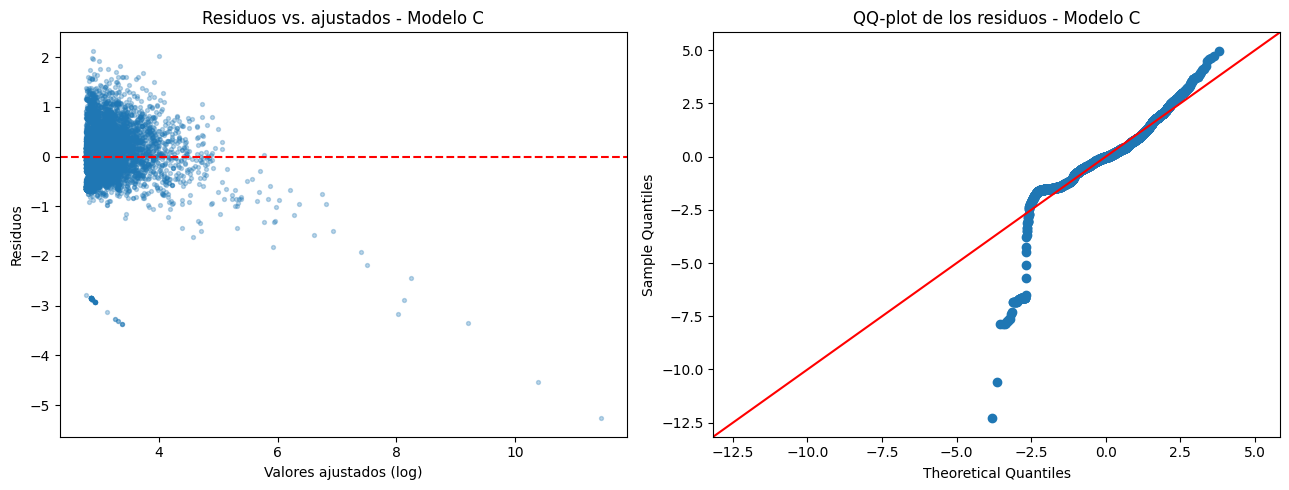


Shapiro-Wilk Modelo C: p-valor=4.10e-48
Breusch-Pagan Modelo C: p-valor=4.99e-231


In [12]:
# Diagnóstico del Modelo C
X_C = sm.add_constant(freight_data[["total_price", "total_weight_g", "n_items"]])
vif_C = pd.DataFrame({
    "variable": X_C.columns,
    "VIF": [variance_inflation_factor(X_C.values, i) for i in range(X_C.shape[1])]
})
print("VIF - Modelo C:")
print(vif_C)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(modelo_C.fittedvalues, modelo_C.resid, s=8, alpha=0.3)
axes[0].axhline(0, color="red", linestyle="--")
axes[0].set_xlabel("Valores ajustados (log)")
axes[0].set_ylabel("Residuos")
axes[0].set_title("Residuos vs. ajustados - Modelo C")

sm.qqplot(modelo_C.resid, line="45", fit=True, ax=axes[1])
axes[1].set_title("QQ-plot de los residuos - Modelo C")
plt.tight_layout()
plt.show()

shapiro_stat_C, shapiro_p_C = stats.shapiro(modelo_C.resid.sample(5000, random_state=32))
bp_stat_C, bp_p_C, _, _ = sm.stats.diagnostic.het_breuschpagan(modelo_C.resid, modelo_C.model.exog)
print(f"\nShapiro-Wilk Modelo C: p-valor={shapiro_p_C:.2e}")
print(f"Breusch-Pagan Modelo C: p-valor={bp_p_C:.2e}")


Análisis del Modelo C:

El VIF de los tres predictores queda cercano a 1, o sea, ya no hay problema de colinealidad (antes peso y volumen tenían VIF ~ 3,3).

Los residuos mejoran, pero no por igual: la normalidad mejora bastante (en el summary, la curtosis baja de 57 a cerca de 13, y en el QQ-plot los puntos quedan mucho más pegados a la recta), aunque el test de Shapiro-Wilk sigue rechazando la normalidad. La heterocedasticidad, en cambio, mejora solo un poco: el estadístico de Breusch-Pagan baja de ~1.349 a ~1.067, una reducción moderada, no una solución completa.

Un detalle importante: el R² de C no se puede comparar directamente con el de A y B, porque ahora el modelo predice el logaritmo del despacho, no el despacho en dólares, son variables distintas. Por eso la comparación entre B y C no la hacemos por R², sino mirando qué tan bien se cumplen los supuestos de la regresión.

Interpretación de los coeficientes de C: como la variable dependiente está en logaritmo, cada coeficiente se interpreta como un cambio porcentual en el despacho. Por ejemplo, `n_items` (coef. = 0,30) significa que, manteniendo todo lo demás constante, cada ítem adicional aumenta el despacho en aproximadamente un 35%.


Recomendación final:

Nos quedamos con el Modelo C.

El bloque pide entender qué determina el costo de despacho, no solo predecirlo, y para eso es importante que el modelo cumpla razonablemente los supuestos de la regresión lineal. El Modelo C resuelve la colinealidad que tenía B (VIF cercano a 1) y mejora la normalidad de los residuos; la heterocedasticidad mejora menos, pero al menos ya no arrastra el problema de variables redundantes de B.

El Modelo B seguiría siendo una opción válida si lo único que importara fuera minimizar el error de predicción en dólares, pero como sus residuos no cumplen los supuestos, sus p-valores e intervalos de confianza no son del todo confiables, algo importante si se quiere usar el modelo para explicar y justificar decisiones, que es el objetivo de este bloque.


---

# Tercer Bloque (30 puntos)

El objetivo ahora es distinto:

> Al momento de procesar un pedido, queremos estimar el riesgo de que llegue después de la fecha comprometida.

El analista ajustó inicialmente el siguiente modelo:


In [13]:
logit_data = delivered[
    delivered["late_delivery"].notna()
    & delivered["total_price"].notna()
    & delivered["total_freight"].notna()
    & delivered["n_items"].notna()
    & delivered["n_categories"].notna()
    & delivered["days_to_carrier"].notna()
    & delivered["remaining_days"].notna()
    & delivered["approval_hours"].notna()
].copy()

modelo_riesgo_1 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + days_to_carrier
    + remaining_days
    + approval_hours
    + C(is_weekend_purchase)
    """,
    data=logit_data
).fit()

print(modelo_riesgo_1.summary())


Optimization terminated successfully.
         Current function value: 0.258033
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                14538
Model:                          Logit   Df Residuals:                    14529
Method:                           MLE   Df Model:                            8
Date:                Sun, 30 Aug 2026   Pseudo R-squ.:                 0.08154
Time:                        23:15:01   Log-Likelihood:                -3751.3
converged:                       True   LL-Null:                       -4084.3
Covariance Type:            nonrobust   LLR p-value:                1.429e-138
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -1.2893      0.220     -5.857      0.000   

              precision    recall  f1-score   support

           0       0.92      1.00      0.96     13362
           1       0.74      0.06      0.11      1176

    accuracy                           0.92     14538
   macro avg       0.83      0.53      0.54     14538
weighted avg       0.91      0.92      0.89     14538



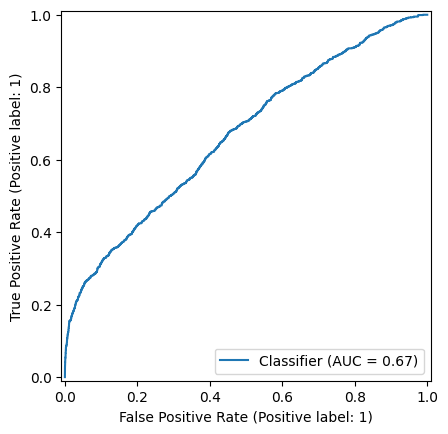

In [14]:
logit_data["prob_1"] = modelo_riesgo_1.predict(logit_data)
logit_data["pred_1"] = (logit_data["prob_1"] >= 0.5).astype(int)

print(classification_report(
    logit_data["late_delivery"].astype(int),
    logit_data["pred_1"]
))

RocCurveDisplay.from_predictions(
    logit_data["late_delivery"].astype(int),
    logit_data["prob_1"]
)

plt.show()


El analista escribe en su informe:

> “El modelo tiene un Accuracy alto, por lo tanto permite detectar correctamente los pedidos que se atrasarán y debería pasar a producción.”


1. identifica qué tipo de modelo utilizó y justificar por qué es o no apropiado para la variable objetivo
2. interpreta correctamente el Odd de la variable `days_to_carrier`
3. evalua la calidad predictiva del modelo utilizando la matriz de confusión, métricas de clasificación y/o curva ROC
4. evalua lo que expuso el analista y determina si es correcto para este problema
5. indica si mantendrías un threshold de `0.5` o si probarías otro valor. No es necesario encontrar un threshold “óptimo”, pero debes justificar tu decisión.

### Tu análisis


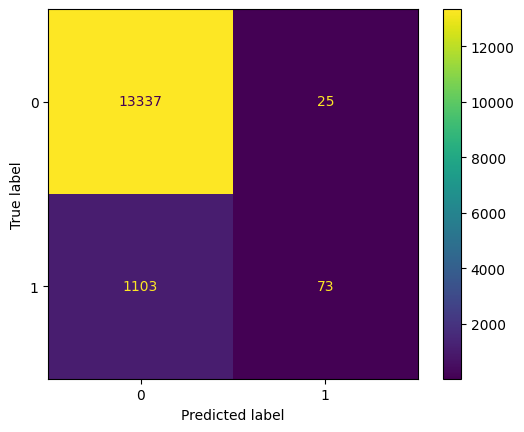

ROC-AUC: 0.6667966805042627
Accuracy si predijéramos siempre 'no atraso': 0.9191085431283533
threshold 0.5: recall=0.062  accuracy=0.922
threshold 0.2: recall=0.178  accuracy=0.913
threshold 0.1: recall=0.401  accuracy=0.780


In [15]:
# 3. Matriz de confusión y ROC-AUC del Modelo 1 (threshold 0.5)
ConfusionMatrixDisplay.from_predictions(logit_data["late_delivery"].astype(int), logit_data["pred_1"])
plt.show()

print("ROC-AUC:", roc_auc_score(logit_data["late_delivery"].astype(int), logit_data["prob_1"]))
print("Accuracy si predijéramos siempre 'no atraso':", 1 - logit_data["late_delivery"].mean())

# 5. Recall y accuracy con distintos threshold
for thr in [0.5, 0.2, 0.1]:
    pred_thr = (logit_data["prob_1"] >= thr).astype(int)
    reporte = classification_report(logit_data["late_delivery"].astype(int), pred_thr, output_dict=True)
    print(f"threshold {thr}: recall={reporte['1']['recall']:.3f}  accuracy={reporte['accuracy']:.3f}")


Respuesta:

1) Tipo de modelo: regresión logística (Logit). Es la correcta porque `late_delivery` es 0/1, y el logit entrega una probabilidad entre 0 y 1 (una regresión lineal común podría dar valores fuera de ese rango).

2) Odds de `days_to_carrier`: coeficiente = 0,111 → exp(0,111) ~ 1,12. Por cada día más que demora el pedido en llegar al transportista, el odds de atraso se multiplica por ~1,12 (sube ~12%), manteniendo todo lo demás constante.

3) Calidad predictiva: el accuracy es 0,92, pero el recall de "atraso" es solo 0,06, el modelo detecta apenas 73 de 1.176 atrasos reales. El ROC-AUC es 0,67.

4) ¿Es correcta la afirmación del analista? No. El accuracy alto es engañoso porque solo el 8% de los pedidos se atrasa (predecir "nunca se atrasa" ya da 0,92 de accuracy). El modelo casi no detecta atrasos reales, así que no lo enviaríamos a producción con esta evidencia.

5) ¿Threshold 0,5? No lo dejaríamos ahí. Si lo que importa es no dejar pasar pedidos en riesgo, conviene bajarlo aunque el accuracy baje un poco:

*   Threshold: 0,5 - Recall 0,06 - Accuracy: 0,92
*   Threshold: 0,2 - Recall 0,18 - Accuracy: 0,91
*   Threshold: 0,1 - Recall 0,40 - Accuracy: 0,78

Un valor cercano a 0,2 parece mejor punto de partida que 0,5.


In [16]:
# Modelo de Riesgo 2: sacamos days_to_carrier, remaining_days y approval_hours,
# porque esos datos todavía NO EXISTEN al momento de procesar el pedido
# (ocurren después de la compra) -> eran fuga de información (Data Leakage).

modelo_riesgo_2 = smf.logit(
    """
    late_delivery
    ~ total_price
    + total_freight
    + n_items
    + n_categories
    + total_weight_g
    + total_volume_cm3
    + C(is_weekend_purchase)
    """,
    data=logit_data
).fit()

print(modelo_riesgo_2.summary())

logit_data["prob_2"] = modelo_riesgo_2.predict(logit_data)
print("\nROC-AUC Modelo 1 (con fuga):", roc_auc_score(logit_data["late_delivery"].astype(int), logit_data["prob_1"]))
print("ROC-AUC Modelo 2 (sin fuga):", roc_auc_score(logit_data["late_delivery"].astype(int), logit_data["prob_2"]))


Optimization terminated successfully.
         Current function value: 0.279982
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:          late_delivery   No. Observations:                14538
Model:                          Logit   Df Residuals:                    14530
Method:                           MLE   Df Model:                            7
Date:                Sun, 30 Aug 2026   Pseudo R-squ.:                0.003414
Time:                        23:15:03   Log-Likelihood:                -4070.4
converged:                       True   LL-Null:                       -4084.3
Covariance Type:            nonrobust   LLR p-value:                 0.0002304
                                  coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------------
Intercept                      -2.0552      0.192    -10.678      0.000   

Análisis: al sacar las variables filtradas, el modelo pierde casi todo su poder: el supuesto R² baja de 0,08 a 0,003, y el ROC-AUC de 0,67 a 0,55 (casi igual al azar). Es decir, buena parte de lo que "predecía" el Modelo 1 en realidad era mirar información del futuro (cuánto se demoró en salir, cuánto margen quedó), no una señal real disponible al momento de la compra.


Recomendación al equipo:

No lo enviaríamos a producción así como está, por dos motivos: usa datos que no existen al momento de procesar el pedido (fuga de información), y con threshold 0,5 casi no detecta atrasos reales (recall 0,06).

Sin esas variables filtradas, el modelo casi no tiene poder predictivo (ROC-AUC 0,55). es decir, hoy no hay señal suficiente al momento de la compra para predecir bien el atraso. Sugerimos no usarlo en producción, y si se necesita algo inmediato, usarlo solo como alerta con un threshold más bajo (ej. 0,2), sabiendo que su poder real es bajo. Lo importante para el equipo es conseguir mejores variables (transportista, zona, temporada), no ajustar el threshold.


---

# Cuarto Bloque (20 puntos)

El equipo de Operaciones necesita anticipar el número de pedidos que recibirá durante los próximos días para planificar su capacidad.

El analista construyó la siguiente serie diaria utilizando los pedidos observados entre enero y julio de 2018


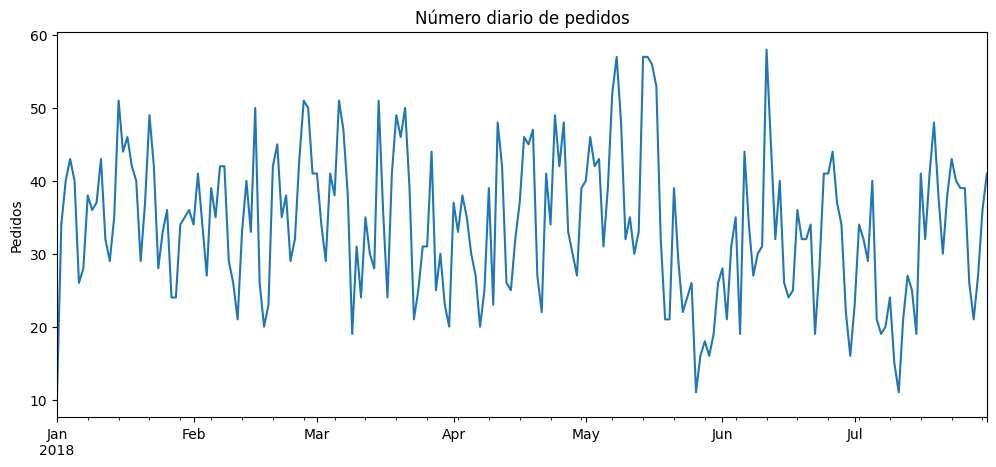

In [17]:
serie_diaria = (
    df
    .dropna(subset=["purchase_date"])
    .groupby("purchase_date")
    .agg(n_orders=("order_id", "nunique"))
    .reset_index()
    .sort_values("purchase_date")
)

serie_diaria = serie_diaria[
    (serie_diaria["purchase_date"] >= "2018-01-01") &
    (serie_diaria["purchase_date"] <= "2018-07-31")
].copy()

serie_diaria.plot(
    x="purchase_date",
    y="n_orders",
    figsize=(12, 5),
    legend=False,
    title="Número diario de pedidos"
)

plt.ylabel("Pedidos")
plt.xlabel("")
plt.show()

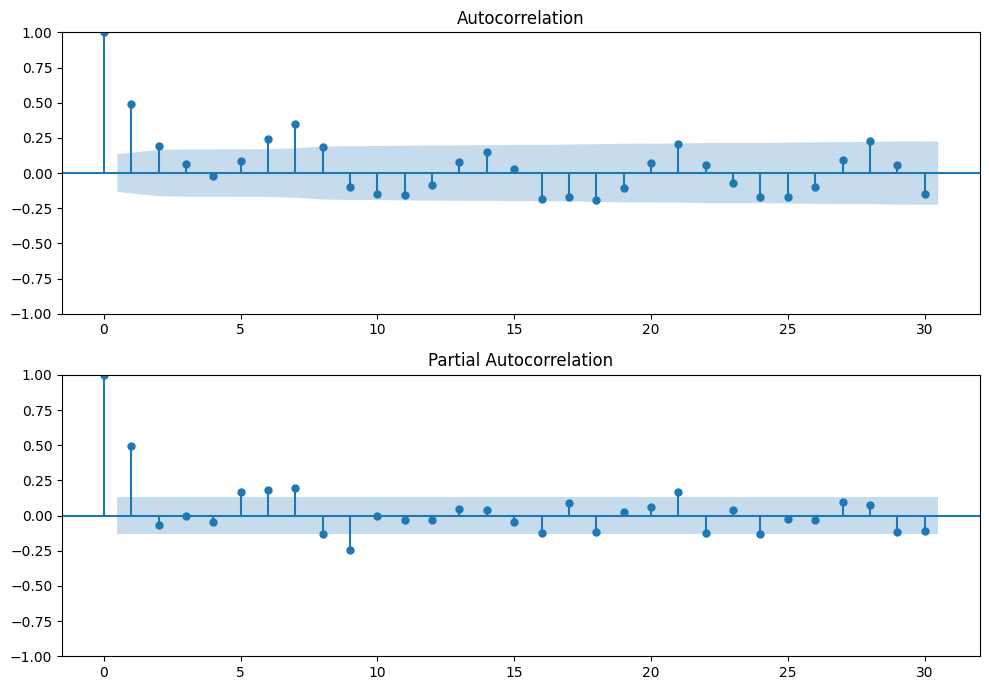

In [18]:
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

serie = (
    serie_diaria
    .set_index("purchase_date")["n_orders"]
    .asfreq("D")
    .fillna(0)
)

fig, ax = plt.subplots(2, 1, figsize=(10, 7))

plot_acf(serie, lags=30, ax=ax[0])
plot_pacf(serie, lags=30, ax=ax[1])

plt.tight_layout()
plt.show()

Finalmente considera que "test" es la semana que el equipo está pronosticando

In [19]:
train = serie.iloc[:-7]
test = serie.iloc[-7:]

> El analista sostiene que la cantidad de pedidos de un día depende de lo ocurrido en los últimos 7 anteriores, y que bastaría un ARIMA(7,0,7)


1. Utilice ACF y PACF para evaluar si la elección de un ARIMA(7,0,7) está justificada a priori.

2. Ajuste el modelo y evalúe sus diagnósticos. ¿Encuentra evidencia de problemas importantes en los residuos?

3. Compare el pronóstico con los últimos 7 días reales. Considerando conjuntamente ACF/PACF, diagnósticos y capacidad predictiva, ¿apoyaría el trabajo del analista? Justifique.

### Tu análisis


In [20]:
# 1. Valores de ACF y PACF (lags 1 a 7), además de los gráficos que ya hizo el analista
from statsmodels.tsa.stattools import acf, pacf

acf_vals = acf(serie, nlags=10)
pacf_vals = pacf(serie, nlags=10)

print("ACF  lags 1-7:", acf_vals[1:8].round(3))
print("PACF lags 1-7:", pacf_vals[1:8].round(3))


ACF  lags 1-7: [ 0.494  0.192  0.064 -0.018  0.089  0.241  0.35 ]
PACF lags 1-7: [ 0.496 -0.068 -0.006 -0.05   0.169  0.191  0.202]


1) ¿ARIMA(7,0,7) se justifica con ACF/PACF?

No se justifica del todo. La PACF solo es fuerte en el lag 1 (0,50); después cae y recién sube un poco en el lag 7 (0,20), eso es el patrón semanal (se parece a hace 7 días), no evidencia de que los 7 lags importen por igual. El analista leyó "depende de los últimos 7 días" como "hay que meter los 7 lags", pero la PACF no respalda eso; algo más simple (solo lag 1 y lag 7) tendría más sentido a priori.


In [21]:
# 2. Ajustamos el ARIMA(7,0,7) tal como lo propone el analista, y revisamos sus diagnósticos
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.stats.diagnostic import acorr_ljungbox
from scipy import stats

modelo_arima = ARIMA(train, order=(7, 0, 7)).fit()
print(modelo_arima.summary())

print("\nLjung-Box (¿quedó autocorrelación en los residuos?):")
print(acorr_ljungbox(modelo_arima.resid, lags=[7, 14], return_df=True))

shapiro_stat, shapiro_p = stats.shapiro(modelo_arima.resid)
print(f"\nShapiro-Wilk residuos: p-valor={shapiro_p:.3f}")


/usr/local/lib/python3.13/dist-packages/statsmodels/base/model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "


                               SARIMAX Results                                
Dep. Variable:               n_orders   No. Observations:                  205
Model:                 ARIMA(7, 0, 7)   Log Likelihood                -700.629
Date:                Sun, 30 Aug 2026   AIC                           1433.259
Time:                        23:15:12   BIC                           1486.427
Sample:                    01-01-2018   HQIC                          1454.764
                         - 07-24-2018                                         
Covariance Type:                  opg                                         
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
const         33.9542      1.510     22.484      0.000      30.994      36.914
ar.L1         -0.1133      0.108     -1.051      0.293      -0.325       0.098
ar.L2         -0.2573      0.102     -2.534      0.0

2) Diagnósticos

El ajuste muestra una alerta real: no convergió bien (14 parámetros para 205 días es mucho). Varios AR no son significativos (`ar.L1`, `L3`, `L4`, `L6`), mientras que todos los MA sí. Los residuos en sí están bien: Ljung-Box no detecta autocorrelación (p=0,98 y 0,86) y Shapiro-Wilk no rechaza normalidad (p=0,33). Los residuos pasan la prueba, pero el modelo está sobre-parametrizado.


In [22]:
# 3. Comparamos el pronóstico del ARIMA(7,0,7) con los 7 días reales,
# y lo comparamos también contra dos baselines simples para tener contexto.
forecast = modelo_arima.forecast(steps=7)

pred_promedio = pd.Series([train.mean()] * 7, index=test.index)   # baseline: predecir el promedio histórico
pred_semana_pasada = pd.Series(train.iloc[-7:].values, index=test.index)  # baseline: repetir la semana anterior

comparacion = pd.DataFrame({
    "real": test,
    "ARIMA(7,0,7)": forecast.round(1),
    "baseline_promedio": pred_promedio.round(1),
    "baseline_semana_pasada": pred_semana_pasada,
})
print(comparacion)

for nombre, pred in [("ARIMA(7,0,7)", forecast), ("baseline_promedio", pred_promedio), ("baseline_semana_pasada", pred_semana_pasada)]:
    print(f"{nombre}: MAE={mean_absolute_error(test, pred):.2f}  RMSE={root_mean_squared_error(test, pred):.2f}")


            real  ARIMA(7,0,7)  baseline_promedio  baseline_semana_pasada
2018-07-25    39        36.300             34.000                      41
2018-07-26    39        38.700             34.000                      48
2018-07-27    26        29.500             34.000                      38
2018-07-28    21        27.300             34.000                      30
2018-07-29    27        33.400             34.000                      38
2018-07-30    36        40.200             34.000                      43
2018-07-31    41        39.000             34.000                      40
ARIMA(7,0,7): MAE=3.63  RMSE=4.18
baseline_promedio: MAE=6.71  RMSE=7.42
baseline_semana_pasada: MAE=7.29  RMSE=8.29


3) ¿Apoyarías el trabajo del analista?

El pronóstico predice bien esta semana (MAE=3,6, ~10% de error) y le gana a dos baselines simples de referencia (promedio: MAE=6,7; repetir la semana anterior: MAE=7,3).

Conclusión: apoyamos el resultado, no el camino. La PACF no justificaba los 7 lags y el modelo no convergió bien, consideramos que funcionó más por prueba y error que por un análisis riguroso. Probaríamos un modelo más simple (lag 1 y lag 7) y, si predice parecido, nos quedaríamos con ese por ser más simple y estable.
